# Análisis de Bolsas de Volatilidad para préstamos respaldados con cryptomonedas

## Resumen del problema

Buscamos, del lado cliente, el tamaño mínimo de una bolsa de volatilidad (colateral extra, puesto desde el arranque) que garantice no ser liquidado dentro de un horizonte (p. ej., 1 año) o hasta el fin del histórico (nuestros datos llegan hasta junio 2025).

En lugar de simular decisiones, intereses o trading, hacemos un cálculo determinista: medimos cuánto podría caer el precio desde el inicio y cuánto colateral adicional haría falta para que, aun en el peor punto de ese trayecto, el LTV nunca cruce el umbral de liquidación.

Este extra adicional, lo podemos guardar y utilizar en staking, para generar retornos pasivos para el cliente y la empresa. En caso de caida podemos usarlo para que no muera el préstamo.

### ¿Cómo lo atacaremos?

Dado que tenemos datos del precio del BTC y ETH por minuto, para cachar correctamente cualquier caída del valor de la criptomoneda, el problema puede resultar computacionalmente costoso, pues si tenemos 2 millones de lecturas, tendremos que hacer el cálculo 2 millones de veces, teniendo un algoritmo de orden $O(n)$ (Por cada entrada, un cálculo).

Para hacerlo mucho más eficiente y rápido, usamos Segment Tree para que en vez de checar entrada por entrada para encontrar el valor que desate nuestra alerta de liquidación, podamos partir los datos localizar rápidamente el siguiente cruce de umbral sin revisar uno por uno. Esto hace que nuestro algoritmo sea de orden $log(n)$, teniendo resultados mucho más rápidos.

## Importamos los Datos, las Funciones y definimos los Parámetros

### Importaciones

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from utils.volatility_buffer_optimizer import (
    load_price_df,
    compute_required_buffer_distribution,
    find_buffer_for_target_success,
    summarize_for_coin,
)
df = load_price_df("../data/processed/historic_prices.csv")

import ipywidgets as widgets
from IPython.display import display, clear_output

### Parámetros

Aquí tendremos nuestra configuración para la simulación: 
1. LTV_INICIAL será nuestro LOAN TO VALUE inicial, es decir, el monto de un préstamo respecto al valor de la criptomoneda que lo respalda
2. LTV_LIQUIDACION será el valor al cual tendremos que liquidar el préstamo, es decir, umbral en el que la garantía del préstamo se liquida automáticamente para cubrir la deuda. 
3. VALOR_PRESTAMO_USD es el valor del préstamo base para las simulaciones

In [2]:
LTV_INICIAL = 0.50
LTV_LIQUIDACION  = 0.80
VALOR_PRESTAMO_USD = 10_000

## Creamos las distribuciones

La función compute_required_buffer_distribution recibe los datos, la moneda, el LTV, Liquidacion, valor del prestamo y 2 parámetros especiales:

- mode: 2 modos - "end" y "window", que definirá si se verá el préstamo desde inicio a fin o en un horizonte cercano respectivamente. Si se escoge "window" se debe agregar el parámetro window_minutes, donde se tendrá que poner en minutos hasta cuando debe durar el préstamo. Si se escoge "end" corre con todos los datos de inicio a fin.

- start_stride: cada cuantos minutos hace un chequeo, si se pone 1, entonces cada minuto revisa la actualización de precio, si se pone 60, entonces cada hora, etc. 

Esto regresa un df con la fecha de inicio, el valor de la criptomoneda inicial, el valor mínimo que alcanzó la criptomoneda, el % sobre el valor del colateral inicial que se debe agregar si no se quiere liquidar (Bolsa de Volatilidad) y este % en USD

### Para BTC

In [3]:
dist_btc = compute_required_buffer_distribution(
    price_df=df,
    coin="BTC",
    init_ltv=LTV_INICIAL,
    liq_ltv=LTV_LIQUIDACION,
    principal_usd=VALOR_PRESTAMO_USD,
    mode="end",
    start_stride=1
)
print(dist_btc.shape)
dist_btc.head()

(2359028, 5)


,fecha_inicio,p0,pmin,buffer_pct_of_init_collateral,buffer_usd_at_p0
0,2021-01-01 00:01:00,29009.91,15513.84,0.168711,3374.217795
1,2021-01-01 00:02:00,28989.30,15513.84,0.167881,3357.611655
2,2021-01-01 00:03:00,28982.69,15513.84,0.167614,3352.285765
3,2021-01-01 00:04:00,28975.65,15513.84,0.167331,3346.613411
4,2021-01-01 00:05:00,28937.11,15513.84,0.165778,3315.560493


### Para ETH

In [4]:
dist_eth = compute_required_buffer_distribution(
    price_df=df,
    coin="ETH",
    init_ltv=LTV_INICIAL,
    liq_ltv=LTV_LIQUIDACION,
    principal_usd=VALOR_PRESTAMO_USD,
    mode="end",            
    start_stride=1
)
print(dist_eth.shape)
dist_eth.head()

(2359028, 5)


,fecha_inicio,p0,pmin,buffer_pct_of_init_collateral,buffer_usd_at_p0
0,2021-01-01 00:01:00,738.74,715.22,0.0,0.0
1,2021-01-01 00:02:00,737.82,715.22,0.0,0.0
2,2021-01-01 00:03:00,737.43,715.22,0.0,0.0
3,2021-01-01 00:04:00,736.89,715.22,0.0,0.0
4,2021-01-01 00:05:00,735.69,715.22,0.0,0.0


### ¿Cómo calculamos esta bolsa?

El cálculo es relativamente sencillo:

Sea $P$ el valor del préstamo en USD, $p_0$ el precio al inicio, $p_min$ el mínimo precio que alcanza el colateral, $L_0$ el LTV inicial y %L_liq$ el LTV de liquidación, tenemos:

1. Colateral inicial $c_0$:
$$ c_0 = \frac{P}{L_0 p_0}$$

2. Colateral mínimo requerido para no ser liquidado $c_min$:
$$ c_{min} = \frac{P}{L_{liq} p_{min}}$$

3. Bolsa Volatilidad
$$ \textrm{buffer} = \text{max}(0, \frac{c_{min}}{c_0}-1)$$

## Analizamos distintos casos

También queremos ver, dentro de todos estos ejemplos de préstamos, cuanto tendría que ser el tamaño de bolsa mínima para no liquidarse. 

Mostremos esto con un ejemplo:

Si yo quisiera que en un 99% de los casos no se liquidara mi préstamo dentro de nuestros datos históricos, cuanto colateral adicional tendría que tener, dados mis parámetros iniciales (ltv, liquidación y valor del préstamo)?

Para esto usamos nuestra función find_buffer_for_target_success que recibe nuestra distribución de arriba, nuestro % de los casos en el que queremos que no se liquide y una métrica, en nuestro caso la Bolsa de Volatilidad o el % sobre el colateral que tendríamos que haber guardado desde el inicio:

In [5]:
buf99_pct_btc = find_buffer_for_target_success(dist_btc, q=0.99, metric="buffer_pct_of_init_collateral")
buf99_pct_eth = find_buffer_for_target_success(dist_eth, q=0.99, metric="buffer_pct_of_init_collateral")
print("BTC buffer pct for 99% success:", buf99_pct_btc)
print("ETH buffer pct for 99% success:", buf99_pct_eth)

BTC buffer pct for 99% success: 1.518650141583257
ETH buffer pct for 99% success: 2.1544694451655135


La función summarize_for_coin hace lo mismo, pero nos permite saltarnos la función de distribución, ajustando todos los parámetros desde de esta misma función, como el LTV, el modo, y los strides. Además, nos da un resumen más completo.

In [6]:
summary_btc = summarize_for_coin(
    price_df=df,
    coin="BTC",
    init_ltv=LTV_INICIAL,
    liq_ltv=LTV_LIQUIDACION,
    principal_usd=VALOR_PRESTAMO_USD,
    mode="end",
    start_stride=1,
    #--------------------------
    # CAMBIAMOS EL UMBRAL AQUI
    target_q=0.99
    #-------------------------
)
summary_btc

{'coin': 'BTC',
 'mode': 'end',
 'window_minutes': nan,
 'init_ltv': 0.5,
 'liq_ltv': 0.8,
 'target_q': 0.99,
 'buffer_pct_of_init_collateral@q': 1.518650141583257,
 'buffer_coins@q (using median p0)': 0.7093393457736508,
 'buffer_usd_at_p0@q': 30373.002831665137,
 'n_starts': 2359028}

In [7]:
summary_eth = summarize_for_coin(
    price_df=df,
    coin="ETH",
    init_ltv=LTV_INICIAL,
    liq_ltv=LTV_LIQUIDACION,
    principal_usd=VALOR_PRESTAMO_USD,
    mode="end",
    start_stride=1,
    #--------------------------
    # CAMBIAMOS EL UMBRAL AQUI
    target_q=0.99
    #-------------------------
)
summary_eth

{'coin': 'ETH',
 'mode': 'end',
 'window_minutes': nan,
 'init_ltv': 0.5,
 'liq_ltv': 0.8,
 'target_q': 0.99,
 'buffer_pct_of_init_collateral@q': 2.1544694451655135,
 'buffer_coins@q (using median p0)': 18.864765819357245,
 'buffer_usd_at_p0@q': 43089.38890331027,
 'n_starts': 2359028}

# Gráficas

Estas gráficas nos ayudarán a visualizar el comportamiento de la Bolsa de Volatilidad, dado un cambio en el ltv_inicial, ltv_liquidación y la moneda

### Helpers

In [8]:
# =====================================================================================
# 1. Parámetros fijos del experimento 
# =====================================================================================

PRINCIPAL_USD = 10_000  
MODE          = "end"   
START_STRIDE  = 1      

# =====================================================================================
# 2. Helpers
# =====================================================================================

def build_quantile_curve_for_coin(
    df_prices: pd.DataFrame,
    coin: str,
    init_ltv: float,
    liq_ltv: float,
) -> dict:
    """
    Calcula:
      - q_grid: array de cuantiles (0..0.99)
      - y_grid: bolsa requerida (fracción del colateral inicial) en cada cuantil
      - stats: dict con cuantiles puntuales que nos interesan
      - n_starts: cuántos inicios evaluamos
    Usa:
      - PRINCIPAL_USD global
      - MODE global ("end")
      - START_STRIDE global (1)
    """
    dist = compute_required_buffer_distribution(
        price_df=df_prices,
        coin=coin,
        init_ltv=init_ltv,
        liq_ltv=liq_ltv,
        principal_usd=PRINCIPAL_USD,
        mode=MODE,
        start_stride=START_STRIDE,
    )

    s = (
        pd.Series(dist["buffer_pct_of_init_collateral"])
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    q_grid = np.linspace(0.0, 0.99, 200)  # 0% → 99%
    y_grid = s.quantile(q_grid)

    # cuantiles puntuales solicitados
    QLIST = [0.99, 0.95, 0.90, 0.85, 0.80, 0.50]
    stats = {f"q_{int(q*100)}": float(s.quantile(q)) for q in QLIST}

    return {
        "coin": coin,
        "q_grid": q_grid,
        "y_grid": y_grid,
        "stats": stats,
        "n_starts": len(dist),
    }

def plot_curves(curves: list, principal_usd: float):
    """
    Dibuja una sola figura.
    - Si curves tiene 1 elemento → una línea.
    - Si curves tiene 2 elementos → líneas sobre la MISMA gráfica (BTC y ETH).
    Agrega nota del monto del préstamo.
    """
    plt.figure(figsize=(7,4))
    for c in curves:
        label = c["coin"]
        plt.plot(c["q_grid"] * 100, c["y_grid"], label=label)

    plt.title("Bolsa requerida vs Nivel de supervivencia")
    plt.xlabel("Nivel de supervivencia (≥ q%)")
    plt.ylabel("Bolsa / Colateral inicial (fracción)")
    plt.grid(True)
    if len(curves) > 1:
        plt.legend()

    # Nota sobre el monto del préstamo
    plt.text(
        0.02, 0.95,
        f"Para un préstamo de ${principal_usd:,.0f} USD",
        transform=plt.gca().transAxes,
        fontsize=9,
        verticalalignment="top"
    )

    plt.show()

def print_summaries(curves: list):
    """
    Imprime para cada coin:
    - n_starts evaluados
    - Bolsa necesaria (fracción del colateral inicial) para 99%,95%,90%,85%,80%,50%
    """
    for c in curves:
        stats = c["stats"]
        print(f"Resumen {c['coin']}:")
        print(f"  inicios evaluados (n_starts): {c['n_starts']}")
        print(f"  Para sobrevivir ≥99%  de los escenarios: {stats['q_99']:.4f} x colateral inicial")
        print(f"  Para sobrevivir ≥95%  de los escenarios: {stats['q_95']:.4f} x colateral inicial")
        print(f"  Para sobrevivir ≥90%  de los escenarios: {stats['q_90']:.4f} x colateral inicial")
        print(f"  Para sobrevivir ≥85%  de los escenarios: {stats['q_85']:.4f} x colateral inicial")
        print(f"  Para sobrevivir ≥80%  de los escenarios: {stats['q_80']:.4f} x colateral inicial")
        print(f"  Para sobrevivir ≥50%  de los escenarios: {stats['q_50']:.4f} x colateral inicial")
        print("")

# =====================================================================================
# 3. Widgets visibles
# =====================================================================================

coin_dropdown = widgets.Dropdown(
    options=[("BTC", "BTC"), ("ETH", "ETH"), ("Ambas (BTC y ETH)", "BOTH")],
    value="BTC",
    description="Moneda:"
)

init_ltv_slider = widgets.FloatSlider(
    value=0.50,
    min=0.10,
    max=0.90,
    step=0.01,
    readout_format=".2f",
    description="LTV inicial:"
)

liq_ltv_slider = widgets.FloatSlider(
    value=0.80,
    min=0.40,
    max=0.92,
    step=0.01,
    readout_format=".2f",
    description="LTV liquidación:"
)

output = widgets.Output()

def update_plot(*args):
    with output:
        clear_output()

        coin_sel = coin_dropdown.value
        init_ltv = init_ltv_slider.value
        liq_ltv  = liq_ltv_slider.value

        curves = []
        if coin_sel == "BOTH":
            # calculamos BTC y ETH y graficamos juntos
            curves.append(build_quantile_curve_for_coin(df, "BTC", init_ltv, liq_ltv))
            curves.append(build_quantile_curve_for_coin(df, "ETH", init_ltv, liq_ltv))
        else:
            curves.append(build_quantile_curve_for_coin(df, coin_sel, init_ltv, liq_ltv))

        plot_curves(curves, PRINCIPAL_USD)
        print_summaries(curves)

### Widget

In [9]:
for w in [coin_dropdown, init_ltv_slider, liq_ltv_slider]:
    w.observe(update_plot, names="value")

# Layout de control
controls_box = widgets.VBox([
    widgets.HBox([coin_dropdown]),
    widgets.HBox([init_ltv_slider, liq_ltv_slider]),
])

display(controls_box, output)

update_plot()

Output()

# Precios Futuros

## Simulación de Precios Futuros (Monte Carlo con retornos históricos)

### ¿Qué estamos haciendo?
Estamos generando trayectorias simuladas del precio futuro de BTC/ETH usando un enfoque de Monte Carlo.  
La idea no es predecir “el precio va a ser X”, sino generar *muchos futuros posibles* coherentes con la forma en que el activo se ha movido históricamente.

### Metodología
1. Partimos de una serie histórica de precios (por ejemplo, BTC cada minuto u hora).
2. Calculamos los **retornos porcentuales paso a paso**:  
   $$( r_t = \frac{P_t}{P_{t-1}} - 1 )$$
3. Estimamos una distribución empírica de esos retornos usando *bootstrap + KDE*:
   - Re-muestreamos retornos reales al azar (con reemplazo).
   - Les agregamos un pequeño ruido gaussiano para suavizar.
   - Esto mantiene las colas gordas y los saltos bruscos típicos de cripto.
4. Simulamos hacia adelante:
   - Elegimos un punto de partida = último precio real observado.
   - Para cada paso futuro, aplicamos un retorno sintético.
   - Repetimos eso muchas veces para obtener muchas trayectorias posibles.

Matemáticamente, cada trayectoria cumple:
$$
P_{t+1} = P_t \cdot (1 + \hat{r}_{t+1})
$$
donde $$\hat{r}_{t+1}$$ viene de la distribución histórica de retornos.

### Horizonte y resolución temporal
- La resolución del paso simulado es la misma que la resolución de los datos de entrada.
  - Si entrenamos con precios por minuto → cada “step” simulado es 1 minuto futuro.
  - Si entrenamos con precios por hora → cada “step” simulado es 1 hora futuro.
- Podemos pedir horizontes largos (ej. 365 días) usando datos agregados por hora para que sea más ligero.

### Output principal
La función principal regresa dos cosas:

1. `price_paths`  
   - DataFrame de forma `(T+1, N)`  
     - `T+1` = número de pasos futuros simulados + la fila inicial  
     - `N` = número de trayectorias simuladas  
   - Cada columna es un escenario posible de precio futuro.
   - La fila 0 es el precio actual (punto de partida).
   - Las filas siguientes son la evolución simulada.

   Ejemplo conceptual:
   - `price_paths.iloc[:, 0]` = trayectoria simulada #0
   - `price_paths.iloc[:, 1]` = trayectoria simulada #1
   - etc.

2. `risk_summary`  
   Diccionario con métricas agregadas al final del horizonte:
   - `start_price`: precio actual usado como punto de partida.
   - `median_final_price`: precio mediano al final del horizonte.
   - `p05_final_price`: percentil 5% del precio final (escenario muy adverso).
   - `prob_drop_20pct_or_more`: probabilidad estimada de caer ≥20%.
   - `prob_drop_40pct_or_more`: probabilidad estimada de caer ≥40%.

   Estas métricas son útiles para gestión de riesgo / margen de colateral porque nos dicen:
   - Que tan feo se puede poner el precio bajo escenarios extremos.
   - Con que probabilidad entramos a zona de margin call o liquidación.

### Gráficas generadas
El simulador también produce:
- **Trayectorias simuladas:** muchas líneas de precio futuro (visión tipo “fan chart”).
- **Bandas de percentiles:** P25 / P50 / P75 a lo largo del tiempo → escenario pesimista / base / optimista.
- **Histograma terminal:** distribución de los rendimientos al final del horizonte → que tan arriba/abajo podemos terminar.

### Cómo interpretar
- No es una predicción determinista.
- Es un generador de mundos posibles consistentes con la volatilidad histórica reciente.
- Podemos enchufar estos mundos a nuestro motor de préstamos para evaluar:
  - probabilidad de tocar Margin Call (LTV ≥ 72%)
  - probabilidad de tocar Liquidación (LTV ≥ 80%)
  - cuánta “bolsa de seguridad” deberíamos exigir.


In [10]:
from utils.bootstrap_mc import (
    run_future_price_simulation,
    extract_scenario_series,
    load_price_series,
)

/Users/rodrigouribe/Desktop/DIVE/Simulaciones-Crypto-Backed-Loans/bolsa_volatilidad/utils/bootstrap_mc.py:278: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  series = series.resample(resample_rule).last().dropna()


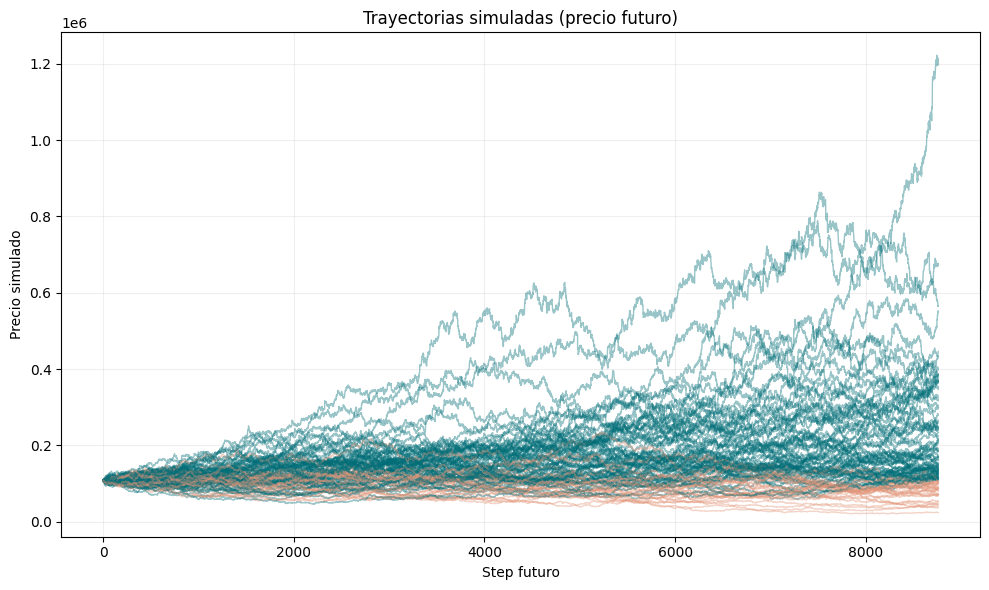

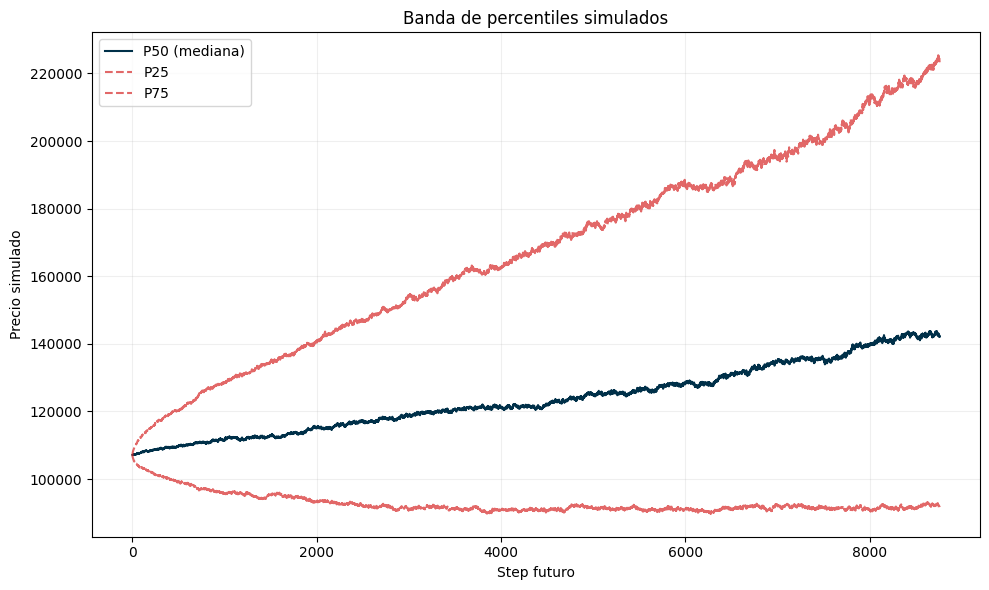

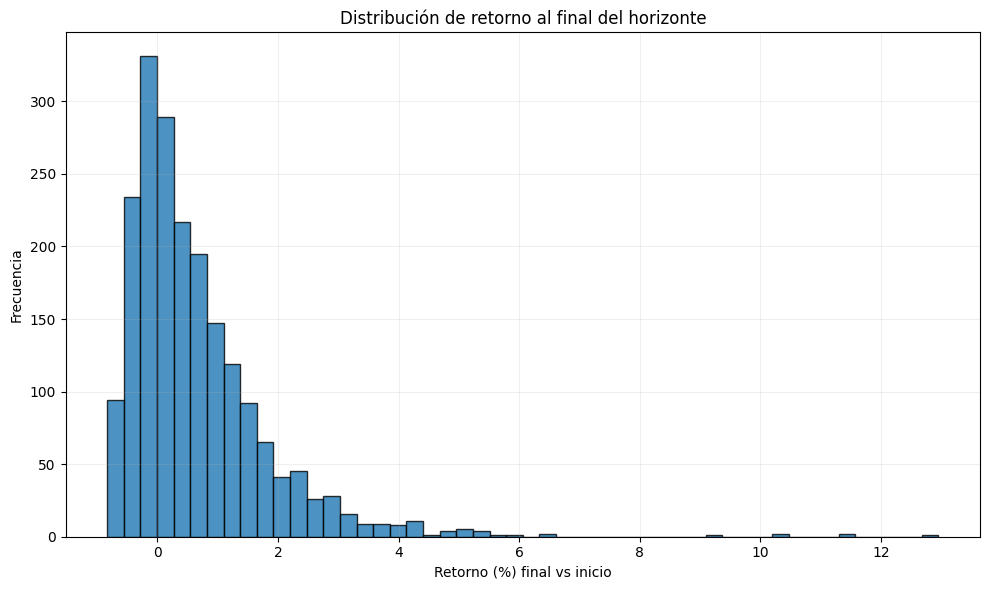

Resumen BTC:
  start_price: 107146.5
  median_final_price: 142194.75697934272
  p05_final_price: 48055.26251534009
  prob_drop_20pct_or_more: 0.2125
  prob_drop_40pct_or_more: 0.108


/Users/rodrigouribe/Desktop/DIVE/Simulaciones-Crypto-Backed-Loans/bolsa_volatilidad/utils/bootstrap_mc.py:278: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  series = series.resample(resample_rule).last().dropna()


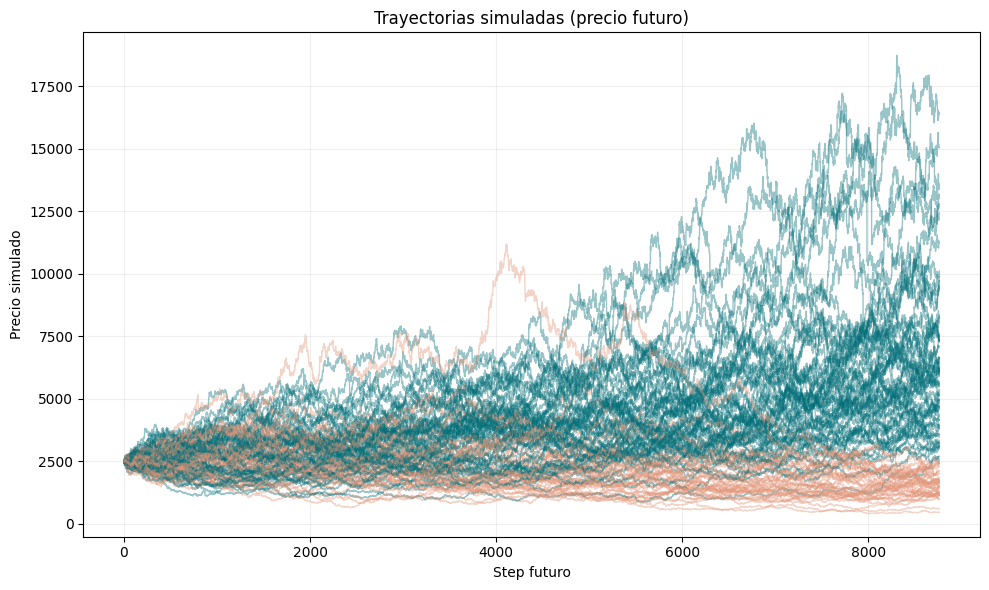

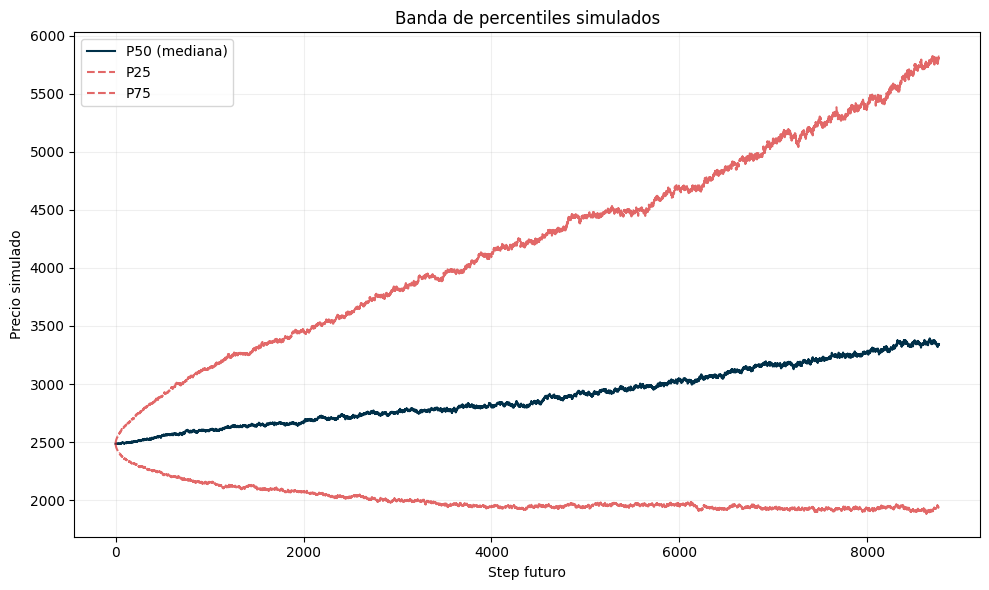

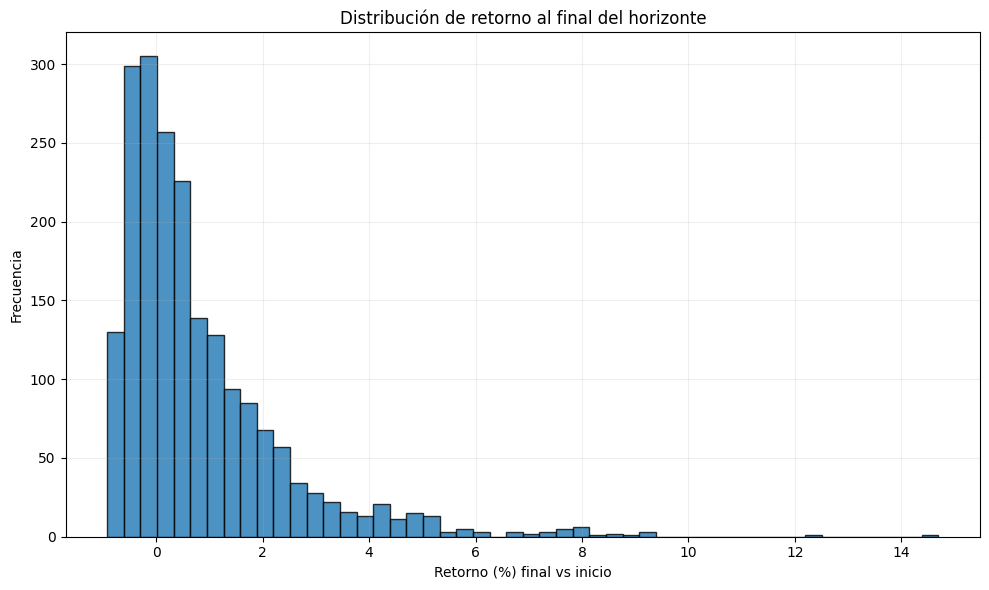

Resumen ETH:
  start_price: 2485.47
  median_final_price: 3340.7745772167627
  p05_final_price: 877.7384532091377
  prob_drop_20pct_or_more: 0.262
  prob_drop_40pct_or_more: 0.156


In [11]:
btc_paths, btc_summary = run_future_price_simulation(
    csv_path="../data/processed/historic_prices.csv",
    asset_col="BTC",
    horizon_days=365,
    n_sims=2000,
    resample_rule="1H",    
    do_plots=True,
)

print("Resumen BTC:")
for k, v in btc_summary.items():
    print(f"  {k}: {v}")

# Ejemplo rápido para ETH (mismo proceso):
eth_paths, eth_summary = run_future_price_simulation(
    csv_path="../data/processed/historic_prices.csv",
    asset_col="ETH",
    horizon_days=365,
    n_sims=2000,
    resample_rule="1H",
    do_plots=True,
)

print("Resumen ETH:")
for k, v in eth_summary.items():
    print(f"  {k}: {v}")

# Bolsa Volatilidad con precios Futuros

Disclaimer: datos basados en comportamiento histórico no son garantía del comportamiento futuro.

In [12]:
# BTC y ETH series
btc_hist_series = load_price_series(
    "../data/processed/historic_prices.csv",
    asset_col="BTC",
    resample_rule="1H",
)

eth_hist_series = load_price_series(
    "../data/processed/historic_prices.csv",
    asset_col="ETH",
    resample_rule="1H",
)

# BTC y ETH escenarios
btc_scenarios = extract_scenario_series(
    price_paths=btc_paths,
    hist_index=btc_hist_series.index,
    pessimistic_q=5,
    base_q=50,
    optimistic_q=95
)

eth_scenarios = extract_scenario_series(
    price_paths=eth_paths,
    hist_index=eth_hist_series.index,
    pessimistic_q=5,    
    base_q=50,
    optimistic_q=95
)

# CREAMOS LOS DF para CADA ESCENARIO
#BTC
btc_future_pess_df = pd.DataFrame({
    "BTC": btc_scenarios["pessimistic"].values
}, index=btc_scenarios["pessimistic"].index)

btc_future_base_df = pd.DataFrame({
    "BTC": btc_scenarios["base"].values
}, index=btc_scenarios["base"].index)

btc_future_opt_df = pd.DataFrame({
    "BTC": btc_scenarios["optimistic"].values
}, index=btc_scenarios["optimistic"].index)

#ETH
eth_future_pess_df = pd.DataFrame({
    "ETH": eth_scenarios["pessimistic"].values
}, index=eth_scenarios["pessimistic"].index)

eth_future_base_df = pd.DataFrame({
    "ETH": eth_scenarios["base"].values
}, index=eth_scenarios["base"].index)

eth_future_opt_df = pd.DataFrame({
    "ETH": eth_scenarios["optimistic"].values
}, index=eth_scenarios["optimistic"].index)

# RESUMENES PARA CADA ESCENARIO

#BTC
summary_btc_pess = summarize_for_coin(
    price_df=btc_future_pess_df,
    coin="BTC",
    init_ltv=LTV_INICIAL,
    liq_ltv=LTV_LIQUIDACION,
    principal_usd=VALOR_PRESTAMO_USD,
    mode="end",
    start_stride=1,
    target_q=0.99,
)
summary_btc_base = summarize_for_coin(
    price_df=btc_future_base_df,
    coin="BTC",
    init_ltv=LTV_INICIAL,
    liq_ltv=LTV_LIQUIDACION,
    principal_usd=VALOR_PRESTAMO_USD,
    mode="end",
    start_stride=1,
    target_q=0.99,
)
summary_btc_opt = summarize_for_coin(
    price_df=btc_future_opt_df,
    coin="BTC",
    init_ltv=LTV_INICIAL,
    liq_ltv=LTV_LIQUIDACION,
    principal_usd=VALOR_PRESTAMO_USD,
    mode="end",
    start_stride=1,
    target_q=0.99,
)

#ETH

summary_eth_pess = summarize_for_coin(
    price_df=eth_future_pess_df,
    coin="ETH",
    init_ltv=LTV_INICIAL,
    liq_ltv=LTV_LIQUIDACION,
    principal_usd=VALOR_PRESTAMO_USD,
    mode="end",
    start_stride=1,
    target_q=0.99,
)

summary_eth_base = summarize_for_coin(
    price_df=eth_future_base_df,
    coin="ETH",
    init_ltv=LTV_INICIAL,
    liq_ltv=LTV_LIQUIDACION,
    principal_usd=VALOR_PRESTAMO_USD,
    mode="end",
    start_stride=1,
    target_q=0.99,
)

summary_eth_opt = summarize_for_coin(
    price_df=eth_future_opt_df,
    coin="ETH",
    init_ltv=LTV_INICIAL,
    liq_ltv=LTV_LIQUIDACION,
    principal_usd=VALOR_PRESTAMO_USD,
    mode="end",
    start_stride=1,
    target_q=0.99,
)

/Users/rodrigouribe/Desktop/DIVE/Simulaciones-Crypto-Backed-Loans/bolsa_volatilidad/utils/bootstrap_mc.py:278: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  series = series.resample(resample_rule).last().dropna()
/Users/rodrigouribe/Desktop/DIVE/Simulaciones-Crypto-Backed-Loans/bolsa_volatilidad/utils/bootstrap_mc.py:278: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  series = series.resample(resample_rule).last().dropna()
